# Heart Health Information Assistant

UCS420 Cognitive Computing Assignment 10

In [1]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt_tab")  # Required for NLTK word_tokenize
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sanga\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sanga\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\sanga\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sanga\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
df = pd.DataFrame([{'query': 'What are common signs of heart disease?', 'intent': 'symptoms'}, {'query': 'Why do I feel chest discomfort?', 'intent': 'symptoms'}, {'query': 'What does shortness of breath indicate?', 'intent': 'symptoms'}, {'query': 'Can heart problems cause dizziness?', 'intent': 'symptoms'}, {'query': 'Why does my heart sometimes beat fast?', 'intent': 'symptoms'}, {'query': 'What are symptoms of an irregular heartbeat?', 'intent': 'symptoms'}, {'query': 'Can unusual tiredness be linked to heart disease?', 'intent': 'symptoms'}, {'query': 'What signs may indicate poor blood circulation?', 'intent': 'symptoms'}, {'query': 'How can I keep my heart healthy?', 'intent': 'prevention'}, {'query': 'What habits reduce the chance of heart disease?', 'intent': 'prevention'}, {'query': 'How does quitting smoking protect the heart?', 'intent': 'prevention'}, {'query': 'Can managing stress improve heart health?', 'intent': 'prevention'}, {'query': 'How often should I check my blood pressure?', 'intent': 'prevention'}, {'query': 'What lifestyle changes help prevent heart problems?', 'intent': 'prevention'}, {'query': 'Does maintaining a healthy weight protect the heart?', 'intent': 'prevention'}, {'query': 'How can I reduce my risk of cardiovascular disease?', 'intent': 'prevention'}, {'query': 'What foods are good for heart health?', 'intent': 'diet'}, {'query': 'Should I reduce salt to protect my heart?', 'intent': 'diet'}, {'query': 'Is eating vegetables helpful for the heart?', 'intent': 'diet'}, {'query': 'What is a heart healthy diet?', 'intent': 'diet'}, {'query': 'Are whole grains good for cardiovascular health?', 'intent': 'diet'}, {'query': 'Which fats should I limit for my heart?', 'intent': 'diet'}, {'query': 'Can too much sugar affect heart health?', 'intent': 'diet'}, {'query': 'What foods contain healthy fats?', 'intent': 'diet'}, {'query': 'How does walking help the heart?', 'intent': 'exercise'}, {'query': 'What exercise is useful for cardiovascular fitness?', 'intent': 'exercise'}, {'query': 'How often should adults exercise for heart health?', 'intent': 'exercise'}, {'query': 'Can cycling improve heart fitness?', 'intent': 'exercise'}, {'query': 'Is regular physical activity good for blood pressure?', 'intent': 'exercise'}, {'query': 'What are safe ways to begin exercising?', 'intent': 'exercise'}, {'query': 'Does swimming support heart health?', 'intent': 'exercise'}, {'query': 'Why is exercise important for circulation?', 'intent': 'exercise'}, {'query': 'What increases the risk of heart disease?', 'intent': 'risk_factors'}, {'query': 'Does smoking increase cardiovascular risk?', 'intent': 'risk_factors'}, {'query': 'Can diabetes affect the heart?', 'intent': 'risk_factors'}, {'query': 'Is high blood pressure a risk factor?', 'intent': 'risk_factors'}, {'query': 'How does family history affect heart disease risk?', 'intent': 'risk_factors'}, {'query': 'Does high cholesterol harm the heart?', 'intent': 'risk_factors'}, {'query': 'Can obesity increase the risk of heart problems?', 'intent': 'risk_factors'}, {'query': 'Does age affect the chance of heart disease?', 'intent': 'risk_factors'}, {'query': 'What is an ECG test used for?', 'intent': 'tests'}, {'query': 'How does an echocardiogram examine the heart?', 'intent': 'tests'}, {'query': 'What does a cholesterol test measure?', 'intent': 'tests'}, {'query': 'Why might a doctor order a stress test?', 'intent': 'tests'}, {'query': 'What is a blood pressure reading?', 'intent': 'tests'}, {'query': 'Can a blood test help assess heart health?', 'intent': 'tests'}, {'query': 'What happens during an ECG?', 'intent': 'tests'}, {'query': 'How is heart function checked?', 'intent': 'tests'}, {'query': 'Why are medicines prescribed for high blood pressure?', 'intent': 'medication'}, {'query': 'What are blood thinners used for?', 'intent': 'medication'}, {'query': 'Should I stop heart medication if I feel better?', 'intent': 'medication'}, {'query': 'Why might a doctor prescribe cholesterol medicine?', 'intent': 'medication'}, {'query': 'Can I change my heart medicine dose myself?', 'intent': 'medication'}, {'query': 'What should I ask before taking a new heart medicine?', 'intent': 'medication'}, {'query': 'Why is it important to take prescribed medicine regularly?', 'intent': 'medication'}, {'query': 'Can medicines help control an irregular heartbeat?', 'intent': 'medication'}, {'query': 'What should I do if someone has severe chest pain?', 'intent': 'emergency'}, {'query': 'Is sudden chest pressure an emergency?', 'intent': 'emergency'}, {'query': 'What should I do if a person collapses and is not breathing normally?', 'intent': 'emergency'}, {'query': 'Can sudden weakness with chest pain be serious?', 'intent': 'emergency'}, {'query': 'When should I call emergency services for possible heart attack?', 'intent': 'emergency'}, {'query': 'What should I do during suspected cardiac arrest?', 'intent': 'emergency'}, {'query': 'Is chest pain with sweating a warning sign?', 'intent': 'emergency'}, {'query': 'What if someone has severe breathlessness and chest pain?', 'intent': 'emergency'}])
print('Number of queries:', len(df))
display(df.head(10))

Number of queries: 64


,query,intent
0,What are common signs of heart disease?,symptoms
1,Why do I feel chest discomfort?,symptoms
2,What does shortness of breath indicate?,symptoms
3,Can heart problems cause dizziness?,symptoms
4,Why does my heart sometimes beat fast?,symptoms
5,What are symptoms of an irregular heartbeat?,symptoms
6,Can unusual tiredness be linked to heart disease?,symptoms
7,What signs may indicate poor blood circulation?,symptoms
8,How can I keep my heart healthy?,prevention
9,What habits reduce the chance of heart disease?,prevention


In [4]:
def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)                                     
    tokens = [re.sub(r'[^a-z]', '', t) for t in tokens]              
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t and t not in stop_words]
    return " ".join(tokens)

df["processed"] = df["query"].apply(preprocess)
df[["query", "processed", "intent"]].head(10)


,query,processed,intent
0,What are common signs of heart disease?,common sign heart disease,symptoms
1,Why do I feel chest discomfort?,feel chest discomfort,symptoms
2,What does shortness of breath indicate?,shortness breath indicate,symptoms
3,Can heart problems cause dizziness?,heart problem cause dizziness,symptoms
4,Why does my heart sometimes beat fast?,heart sometimes beat fast,symptoms
5,What are symptoms of an irregular heartbeat?,symptom irregular heartbeat,symptoms
6,Can unusual tiredness be linked to heart disease?,unusual tiredness linked heart disease,symptoms
7,What signs may indicate poor blood circulation?,sign may indicate poor blood circulation,symptoms
8,How can I keep my heart healthy?,keep heart healthy,prevention
9,What habits reduce the chance of heart disease?,habit reduce chance heart disease,prevention


In [5]:
taxonomy = {
    "Heart conditions": ["Coronary artery disease", "Arrhythmia"],
    "Heart health management": ["Prevention", "Risk factors"],
    "Diagnosis and care": ["Heart tests", "Medication"],
    "Daily health practices": ["Heart healthy diet", "Physical activity"]
}
for category, subcategories in taxonomy.items():
    print(category)
    for subcategory in subcategories:
        print("-", subcategory)

Heart conditions
- Coronary artery disease
- Arrhythmia
Heart health management
- Prevention
- Risk factors
Diagnosis and care
- Heart tests
- Medication
Daily health practices
- Heart healthy diet
- Physical activity


In [6]:
concepts = ["Heart", "Blood", "Blood pressure", "Cholesterol", "Artery", "ECG", "Medication", "Exercise", "Diet", "Smoking", "Diabetes", "Heart disease"]
relationships = [
    ("Heart", "pumps", "Blood"),
    ("Blood pressure", "measures force of", "Blood"),
    ("Cholesterol", "can accumulate in", "Artery"),
    ("Artery", "supplies blood to", "Heart"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Medication", "may help control", "Blood pressure"),
    ("Exercise", "supports", "Heart"),
    ("Diet", "influences", "Cholesterol"),
    ("Smoking", "increases risk of", "Heart disease"),
    ("Diabetes", "increases risk of", "Heart disease"),
    ("High cholesterol", "increases risk of", "Heart disease"),
    ("Heart disease", "may affect", "Blood flow")
]
print("Domain concepts:", concepts)
print("Relationships:")
for relation in relationships:
    print(relation)

Domain concepts: ['Heart', 'Blood', 'Blood pressure', 'Cholesterol', 'Artery', 'ECG', 'Medication', 'Exercise', 'Diet', 'Smoking', 'Diabetes', 'Heart disease']
Relationships:
('Heart', 'pumps', 'Blood')
('Blood pressure', 'measures force of', 'Blood')
('Cholesterol', 'can accumulate in', 'Artery')
('Artery', 'supplies blood to', 'Heart')
('ECG', 'records electrical activity of', 'Heart')
('Medication', 'may help control', 'Blood pressure')
('Exercise', 'supports', 'Heart')
('Diet', 'influences', 'Cholesterol')
('Smoking', 'increases risk of', 'Heart disease')
('Diabetes', 'increases risk of', 'Heart disease')
('High cholesterol', 'increases risk of', 'Heart disease')
('Heart disease', 'may affect', 'Blood flow')


Accuracy: 0.375
Precision: 0.27499999999999997
Recall: 0.375
F1-score: 0.3107142857142857
              precision    recall  f1-score   support

        diet       0.00      0.00      0.00         2
   emergency       1.00      1.00      1.00         2
    exercise       0.67      1.00      0.80         2
  medication       0.00      0.00      0.00         2
  prevention       0.00      0.00      0.00         2
risk_factors       0.33      0.50      0.40         2
    symptoms       0.00      0.00      0.00         2
       tests       0.20      0.50      0.29         2

    accuracy                           0.38        16
   macro avg       0.27      0.38      0.31        16
weighted avg       0.27      0.38      0.31        16



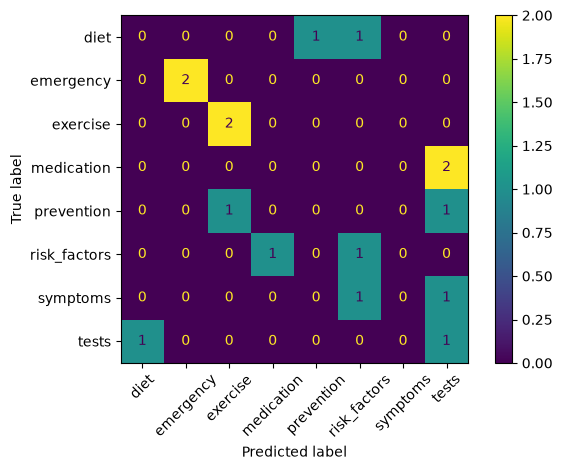

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["processed"], df["intent"], test_size=0.25,
    random_state=42, stratify=df["intent"]
)
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)
predictions = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, predictions, average="weighted", zero_division=0))
print("F1-score:", f1_score(y_test, predictions, average="weighted", zero_division=0))
print(classification_report(y_test, predictions, zero_division=0))

cm = confusion_matrix(y_test, predictions, labels=model.classes_)
plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
plot.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [8]:
knowledge_base = {
    "symptoms": "Possible warning signs include chest discomfort, shortness of breath, unusual fatigue, dizziness and irregular heartbeat. Symptoms can have many causes and need professional assessment.",
    "prevention": "Heart health can be supported by not smoking, staying physically active, eating a balanced diet, managing stress and monitoring blood pressure and cholesterol.",
    "diet": "A heart healthy eating pattern often includes vegetables, fruits, whole grains, beans and suitable sources of unsaturated fats. Limiting excess salt, added sugar and saturated fat may help.",
    "exercise": "Regular physical activity such as walking, cycling or swimming can support cardiovascular fitness. Start gradually and seek medical advice if you have symptoms or a health condition.",
    "risk_factors": "Risk factors can include high blood pressure, high cholesterol, smoking, diabetes, excess weight, age and family history. A healthcare professional can help assess personal risk.",
    "tests": "Common assessments include blood pressure measurement, cholesterol tests, ECG, echocardiogram and sometimes a stress test. A clinician decides which tests are appropriate.",
    "medication": "Heart medicines depend on the condition and may help manage blood pressure, cholesterol or rhythm problems. Take them as prescribed and do not change or stop a dose without medical advice.",
    "emergency": "Possible heart emergencies need immediate medical attention. Call your local emergency number now for severe chest pain, collapse, severe breathlessness or suspected cardiac arrest. Do not drive yourself."
}
for intent, information in knowledge_base.items():
    print(intent, ":", information, "\n")

symptoms : Possible warning signs include chest discomfort, shortness of breath, unusual fatigue, dizziness and irregular heartbeat. Symptoms can have many causes and need professional assessment. 

prevention : Heart health can be supported by not smoking, staying physically active, eating a balanced diet, managing stress and monitoring blood pressure and cholesterol. 

diet : A heart healthy eating pattern often includes vegetables, fruits, whole grains, beans and suitable sources of unsaturated fats. Limiting excess salt, added sugar and saturated fat may help. 

exercise : Regular physical activity such as walking, cycling or swimming can support cardiovascular fitness. Start gradually and seek medical advice if you have symptoms or a health condition. 

risk_factors : Risk factors can include high blood pressure, high cholesterol, smoking, diabetes, excess weight, age and family history. A healthcare professional can help assess personal risk. 

tests : Common assessments include 

In [9]:
emergency_terms = ["severe chest pain", "chest pressure", "cardiac arrest", "collapses", "not breathing", "heart attack", "chest pain with sweating", "severe breathlessness"]
heart_terms = set("heart cardiac cardiovascular chest blood pressure cholesterol artery ecg echocardiogram heartbeat rhythm pulse circulation smoking diabetes exercise diet medication stroke attack fatigue dizziness breathlessness coronary hypertension arrhythmia ticker".split())
health_terms = set("health doctor disease pain symptom treatment medicine medical hospital rash fever cough headache infection skin stomach pregnancy".split())

# Note: The 'emergency' intent is also trained in the classifier as a safety net,
# but Rule 1 (keyword match) takes priority so responses are instant and reliable.

def assistant(query):
    text = query.lower()

    # Rule 1: Emergency escalation – keyword-based for instant, reliable detection
    if any(term in text for term in emergency_terms):
        return "Emergency alert: " + knowledge_base["emergency"]

    # Rule 2: Medication safety override – block dangerous self-medication queries
    if any(term in text for term in ["change my dose", "stop my medicine", "double my dose", "missed dose"]):
        return "Do not change or stop prescribed heart medication without advice from your doctor or pharmacist."

    processed = preprocess(query)
    words = set(processed.split())

    # Rule 3: Unsupported but health-related query – redirect to specialist
    if not words.intersection(heart_terms):
        if words.intersection(health_terms):
            return "This assistant covers heart health information only. Please consult an appropriate healthcare professional for this question."

        # Rule 4: Completely unrecognised query – no heart or health terms detected
        return "I could not identify a supported heart health question. Please ask about heart symptoms, prevention, diet, exercise, risk factors, tests or medication."

    features = vectorizer.transform([processed])
    probabilities = model.predict_proba(features)[0]
    best_index = probabilities.argmax()
    confidence = probabilities[best_index]
    intent = model.classes_[best_index]

    # Rule 5: Low-confidence fallback – classifier not sure enough, ask user to rephrase
    if confidence < 0.20:
        return "I am not confident enough to answer this question. Please rephrase it or consult a healthcare professional."

    return knowledge_base[intent]

print(assistant("How can I improve my heart health?"))


I am not confident enough to answer this question. Please rephrase it or consult a healthcare professional.


In [11]:
# Test queries covering all 5 required test types from the assignment
test_cases = [
    ("What are common signs of heart disease?",         "Intent query: Symptoms"),
    ("How can I protect my heart every day?",           "Intent query: Prevention"),
    ("Which foods are better for my heart?",            "Intent query: Diet"),
    ("Can walking improve my cardiovascular fitness?",  "Intent query: Exercise"),
    ("Does high cholesterol increase heart risk?",      "Intent query: Risk factors"),
    ("What information does an ECG provide?",           "Intent query: Tests"),
    ("Why should I take prescribed blood pressure medicine?", "Intent query: Medication"),
    ("What should I do during severe chest pain?",      "Emergency escalation (Rule 1)"),
    ("What can I do for a skin rash?",                  "Unsupported healthcare query (Rule 3)"),
    ("heart xyzzy quux blorf",                          "Low-confidence query (Rule 5) – verified conf=0.157"),
    ("How can I keep my ticker healthy?",               "Differently worded query")
]
for query, expected in test_cases:
    print("Query   :", query)
    print("Expected:", expected)
    print("Response:", assistant(query))
    print(" " * 60)


Query   : What are common signs of heart disease?
Expected: Intent query: Symptoms
Response: Risk factors can include high blood pressure, high cholesterol, smoking, diabetes, excess weight, age and family history. A healthcare professional can help assess personal risk.
                                                            
Query   : How can I protect my heart every day?
Expected: Intent query: Prevention
Response: Heart health can be supported by not smoking, staying physically active, eating a balanced diet, managing stress and monitoring blood pressure and cholesterol.
                                                            
Query   : Which foods are better for my heart?
Expected: Intent query: Diet
Response: I am not confident enough to answer this question. Please rephrase it or consult a healthcare professional.
                                                            
Query   : Can walking improve my cardiovascular fitness?
Expected: Intent query: Exercise
Response

In [12]:
while True:
    query = input("Enter your heart health question or type exit: ")
    if query.lower().strip() == "exit":
        break
    print(assistant(query))
    print()

Enter your heart health question or type exit:  What are common signs of heart disease?


Risk factors can include high blood pressure, high cholesterol, smoking, diabetes, excess weight, age and family history. A healthcare professional can help assess personal risk.



Enter your heart health question or type exit:  What foods are good for heart health?


A heart healthy eating pattern often includes vegetables, fruits, whole grains, beans and suitable sources of unsaturated fats. Limiting excess salt, added sugar and saturated fat may help.



Enter your heart health question or type exit:  How does walking help the heart?


Regular physical activity such as walking, cycling or swimming can support cardiovascular fitness. Start gradually and seek medical advice if you have symptoms or a health condition.



... (11 outputs left out)

I am not confident enough to answer this question. Please rephrase it or consult a healthcare professional.



Enter your heart health question or type exit:  I have severe chest pain and sweating


Emergency alert: Possible heart emergencies need immediate medical attention. Call your local emergency number now for severe chest pain, collapse, severe breathlessness or suspected cardiac arrest. Do not drive yourself.



Enter your heart health question or type exit:  exit
